In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [5]:
df = pd.read_csv("Census2022sample_F19.csv")

In [7]:
print("Initial shape: ", df.shape)
print(df.head())
print(df.info())

Initial shape:  (1338295, 32)
        QID  DERH_HSIZE  DERH_HHSEX  DERH_HHPOP  DERH_HHAGE  H01_QUARTERS  \
0  10000003           2           2           1          44             5   
1  10000005           4           2           1          41             5   
2  10000008           3           1           2          76             1   
3  10000018           2           2           1          37             1   
4  10000024           1           1           5          34             1   

   H02_MAINDWELLING  H03_TENURE  H04_RDP  H05_WATERPIPED  ...  H12_DVD_PLAYER  \
0                88           8        8               3  ...               2   
1                88           8        8               1  ...               2   
2                 1           4        2               1  ...               2   
3                 1           9        9               1  ...               9   
4                 1           4        2               1  ...               2   

   H12_MOTOR_CAR  H1

In [13]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

numeric_cols = df.select_dtypes(include=[np.number]).columns
categorical_cols = df.select_dtypes(exclude=[np.number]).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

In [14]:
df = df.drop_duplicates()

In [15]:
if 'derh_hhage' in df.columns:
    df['derh_hhage'] = df['derh_hhage'].astype(int)
    df = df[(df['derh_hhage'] >= 0) & (df['derh_hhage'] <= 100)]  # realistic ages

if 'derh_hhsex' in df.columns:
    df['derh_hhsex'] = df['derh_hhsex'].replace({
        1: 'Male',
        2: 'Female'
    })

if 'derh_hhsize' in df.columns:
    df = df[df['derh_hhsize'] <= 20] 

In [16]:
print("Cleaned shape:", df.shape)
print(df.describe(include='all'))

Cleaned shape: (1337956, 32)
                 qid    derh_hsize derh_hhsex    derh_hhpop    derh_hhage  \
count   1.337956e+06  1.337956e+06    1337956  1.337956e+06  1.337956e+06   
unique           NaN           NaN          2           NaN           NaN   
top              NaN           NaN       Male           NaN           NaN   
freq             NaN           NaN     669191           NaN           NaN   
mean    5.441693e+07  3.129947e+00        NaN  1.457916e+00  4.663910e+01   
std     2.541745e+07  2.095343e+00        NaN  9.783518e-01  1.508429e+01   
min     1.000000e+07  1.000000e+00        NaN  1.000000e+00  1.200000e+01   
25%     4.000423e+07  1.000000e+00        NaN  1.000000e+00  3.600000e+01   
50%     6.053945e+07  3.000000e+00        NaN  1.000000e+00  4.600000e+01   
75%     7.101208e+07  4.000000e+00        NaN  1.000000e+00  5.700000e+01   
max     9.133829e+07  1.000000e+01        NaN  5.000000e+00  1.000000e+02   

        h01_quarters  h02_maindwelling    h03_

In [18]:
print(df['derh_hhsex'].value_counts())
print(df['h05_waterpiped'].value_counts())


Male      669191
Female    668765
Name: derh_hhsex, dtype: int64
1    727813
2    322443
7    144396
3     98923
4     27352
5      9807
6      7222
Name: h05_waterpiped, dtype: int64


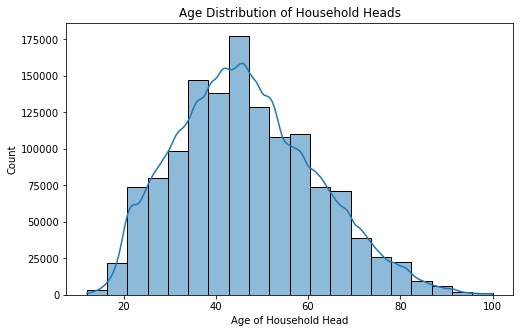

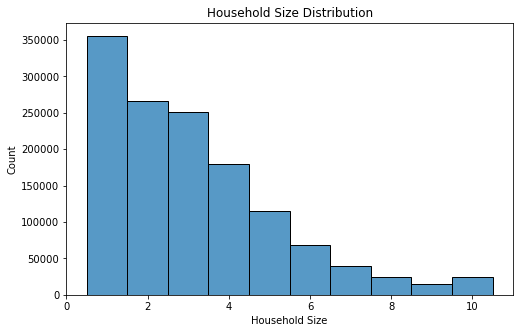

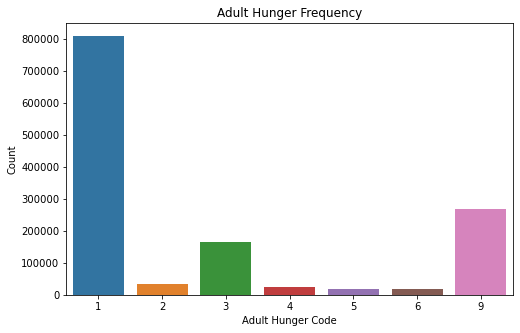

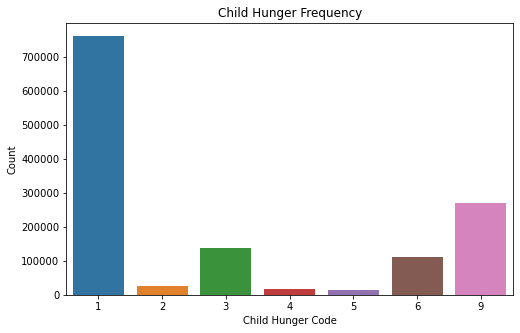

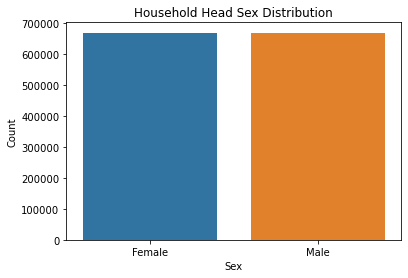

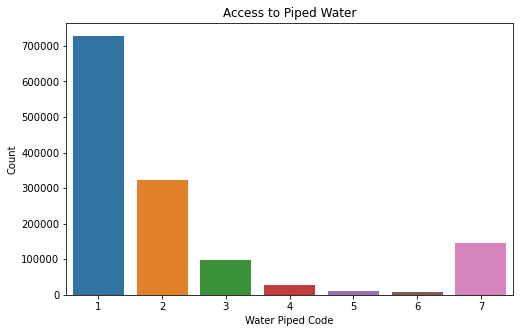

In [23]:
# --- Age distribution of household heads ---
plt.figure(figsize=(8,5))
sns.histplot(df['derh_hhage'], bins=20, kde=True)
plt.title("Age Distribution of Household Heads")
plt.xlabel("Age of Household Head")
plt.ylabel("Count")
plt.show()

# --- Household size distribution ---
plt.figure(figsize=(8,5))
sns.histplot(df['derh_hsize'], bins=10, discrete=True)
plt.title("Household Size Distribution")
plt.xlabel("Household Size")
plt.ylabel("Count")
plt.show()

# --- Adult hunger frequency ---
plt.figure(figsize=(8,5))
sns.countplot(x='a4_adult_hunger', data=df)
plt.title("Adult Hunger Frequency")
plt.xlabel("Adult Hunger Code")
plt.ylabel("Count")
plt.show()

# --- Child hunger frequency ---
plt.figure(figsize=(8,5))
sns.countplot(x='a5_child_hunger', data=df)
plt.title("Child Hunger Frequency")
plt.xlabel("Child Hunger Code")
plt.ylabel("Count")
plt.show()

# --- Household head sex distribution ---
plt.figure(figsize=(6,4))
sns.countplot(x='derh_hhsex', data=df)
plt.title("Household Head Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

# --- Access to piped water ---
plt.figure(figsize=(8,5))
sns.countplot(x='h05_waterpiped', data=df)
plt.title("Access to Piped Water")
plt.xlabel("Water Piped Code")
plt.ylabel("Count")
plt.show()

Household Head Sex vs Access to Piped Water
h05_waterpiped       1       2      3      4     5     6      7
derh_hhsex                                                     
Female          352179  163960  50637  14353  5170  3779  78687
Male            375634  158483  48286  12999  4637  3443  65709


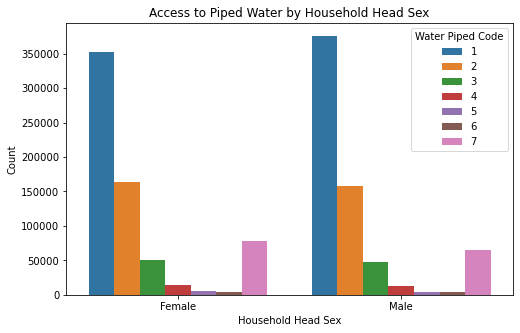

Household Size vs Adult Hunger
a4_adult_hunger       1     2      3     4     5     6      9
derh_hsize                                                   
1                208876  8857  44450  6760  6048  7766  72865
2                149741  5742  27458  3851  2975  3648  72405
3                126618  5028  24275  3294  2425  2363  87208
4                117793  4651  22104  2928  2101  1890  28380
5                 82625  3387  17010  2234  1613  1265   6422
6                 49655  2118  11294  1591  1098   683   1385
7                 29223  1310   7080  1050   708   388    375
8                 17171   742   4515   704   464   206    187
9                 10273   491   2941   416   285   160     90
10                16459   864   5169   878   545   229    153


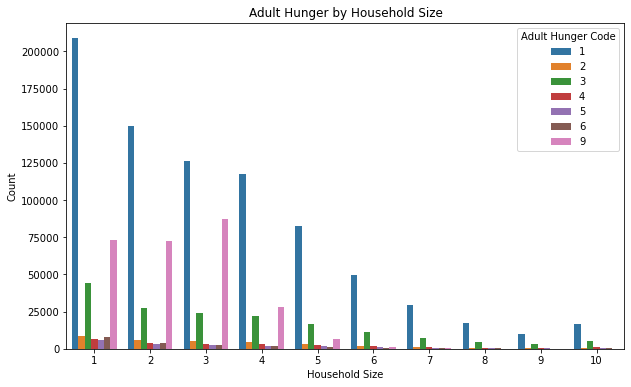

Household Head Sex vs Adult Hunger
a4_adult_hunger       1      2      3      4     5     6       9
derh_hhsex                                                      
Female           401906  16948  88209  12264  9246  8845  131347
Male             406528  16242  78087  11442  9016  9753  138123


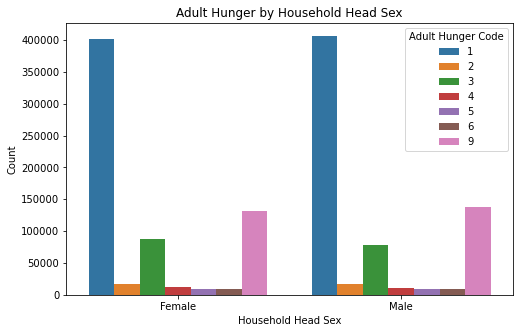

Dwelling Type vs Tenure
h03_tenure             1      2      3       4       5      6     7      8  \
h02_maindwelling                                                             
1                 105182  29080  47645  344620  175533  20963  5384      0   
2                   1760    392   2429   18484   17701   2723   480      0   
3                  17946   4171   2452    3761    2667    367   234      0   
4                   1064    163   1206    1232     203     59    60      0   
5                   1737    229   1516    1832     247     72    51      0   
6                   2463    858   1018    5122    2713    358   161      0   
7                  19582   2112   1596   11092    9526   1066   371      0   
8                  13948   1257   1017    8408   12782   1021   279      0   
9                   6270    988   1056   14412   29673   2031   315      0   
10                    67     23      4      37      80     17     6      0   
11                   484    152    146  

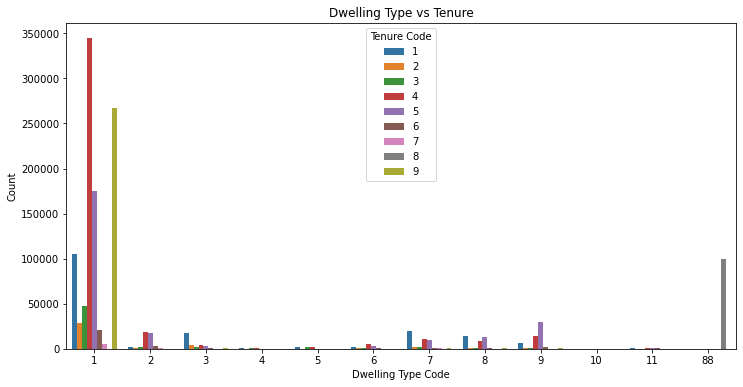

Mean household size by sex of household head:
derh_hhsex
Female    3.483701
Male      2.776418
Name: derh_hsize, dtype: float64

Average age of household head by tenure type:
h03_tenure
1    38.137693
2    45.274851
3    46.627544
4    51.481230
5    47.600972
6    48.664886
7    46.399947
8    44.232252
9    44.626137
Name: derh_hhage, dtype: float64


In [24]:
# --- Cross-tabulation: Household head sex vs access to piped water ---
ct_sex_water = pd.crosstab(df['derh_hhsex'], df['h05_waterpiped'])
print("Household Head Sex vs Access to Piped Water")
print(ct_sex_water)

plt.figure(figsize=(8,5))
sns.countplot(x='derh_hhsex', hue='h05_waterpiped', data=df)
plt.title("Access to Piped Water by Household Head Sex")
plt.xlabel("Household Head Sex")
plt.ylabel("Count")
plt.legend(title="Water Piped Code")
plt.show()

# --- Cross-tabulation: Household size vs adult hunger ---
ct_size_hunger = pd.crosstab(df['derh_hsize'], df['a4_adult_hunger'])
print("Household Size vs Adult Hunger")
print(ct_size_hunger)

plt.figure(figsize=(10,6))
sns.countplot(x='derh_hsize', hue='a4_adult_hunger', data=df)
plt.title("Adult Hunger by Household Size")
plt.xlabel("Household Size")
plt.ylabel("Count")
plt.legend(title="Adult Hunger Code")
plt.show()

# --- Cross-tabulation: Household head sex vs adult hunger ---
ct_sex_hunger = pd.crosstab(df['derh_hhsex'], df['a4_adult_hunger'])
print("Household Head Sex vs Adult Hunger")
print(ct_sex_hunger)

plt.figure(figsize=(8,5))
sns.countplot(x='derh_hhsex', hue='a4_adult_hunger', data=df)
plt.title("Adult Hunger by Household Head Sex")
plt.xlabel("Household Head Sex")
plt.ylabel("Count")
plt.legend(title="Adult Hunger Code")
plt.show()

# --- Dwelling type vs tenure ---
ct_dwelling_tenure = pd.crosstab(df['h02_maindwelling'], df['h03_tenure'])
print("Dwelling Type vs Tenure")
print(ct_dwelling_tenure)

plt.figure(figsize=(12,6))
sns.countplot(x='h02_maindwelling', hue='h03_tenure', data=df)
plt.title("Dwelling Type vs Tenure")
plt.xlabel("Dwelling Type Code")
plt.ylabel("Count")
plt.legend(title="Tenure Code")
plt.show()

# --- Summary statistics examples ---
print("Mean household size by sex of household head:")
print(df.groupby('derh_hhsex')['derh_hsize'].mean())

print("\nAverage age of household head by tenure type:")
print(df.groupby('h03_tenure')['derh_hhage'].mean())